# Análisis del SMS Spam Collection

Exploración del dataset y de los modelos entrenados con `spamclf`. Antes de ejecutar: `spamclf download`.

1. ¿Cómo son los datos?
2. ¿Coincide el Naive Bayes escrito a mano con el de scikit-learn?
3. ¿Qué umbral de decisión conviene?
4. ¿En qué mensajes se equivoca el modelo?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

from spamclf.data import load_dataset, split_dataset
from spamclf.models import ModelName
from spamclf.plots import STYLE, BLUE, ORANGE
from spamclf.training import train_model

plt.rcParams.update(STYLE)
pd.set_option("display.max_colwidth", 110)

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
DATA = ROOT / "data" / "SMSSpamCollection.tsv"

## 1. Los datos

Cada fila es un SMS etiquetado como `ham` (legítimo) o `spam`.

In [2]:
raw = load_dataset(DATA, deduplicate=False)
df = load_dataset(DATA)
print(f"{len(raw):,} mensajes; {len(raw) - len(df):,} duplicados exactos eliminados")
df["label"].value_counts().to_frame("mensajes").assign(
    proporcion=lambda t: (t["mensajes"] / t["mensajes"].sum()).round(3)
)

5,574 mensajes; 403 duplicados exactos eliminados


,mensajes,proporcion
label,,
ham,4518,0.874
spam,653,0.126


Dos cosas condicionan todo lo demás:

- **Hay duplicados.** Si se quedaran, el mismo mensaje podría caer en entrenamiento y en test, y las métricas saldrían infladas. `load_dataset` los elimina por defecto.
- **Las clases están desbalanceadas** (~13 % de spam). Un modelo que responda siempre `ham` acierta el 87 %, así que la *accuracy* dice poco: hay que mirar precisión y recall.

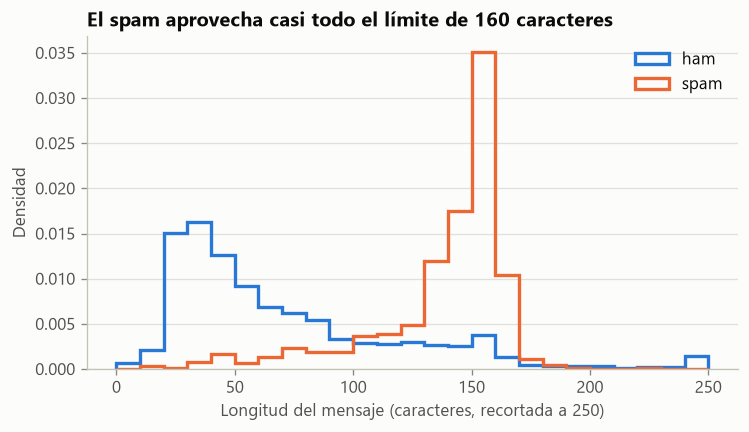

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4518.0,70.9,56.6,2.0,34.0,53.0,91.0,910.0
spam,653.0,137.7,29.8,13.0,132.0,148.0,157.0,223.0


In [3]:
df["longitud"] = df["text"].str.len()
bins = np.arange(0, 260, 10)

fig, ax = plt.subplots(figsize=(7, 3.6), dpi=120)
for label, color in (("ham", BLUE), ("spam", ORANGE)):
    ax.hist(
        df.loc[df["label"] == label, "longitud"].clip(upper=250),
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=color,
        label=label,
    )
ax.set_xlabel("Longitud del mensaje (caracteres, recortada a 250)")
ax.set_ylabel("Densidad")
ax.set_title(
    "El spam aprovecha casi todo el límite de 160 caracteres", loc="left", fontweight="bold"
)
ax.grid(True, axis="y")
ax.legend()
plt.show()

df.groupby("label")["longitud"].describe().round(1)

## 2. Naive Bayes a mano frente a scikit-learn

`ScratchMultinomialNB` está escrito solo con NumPy. Si la implementación es correcta, debe dar **las mismas probabilidades** que `MultinomialNB`.

In [4]:
split = split_dataset(df)
ours = train_model(ModelName.NB_SCRATCH, split.X_train, split.y_train)
reference = train_model(ModelName.NB, split.X_train, split.y_train)

difference = np.abs(ours.predict_proba(split.X_test) - reference.predict_proba(split.X_test))
print(f"Diferencia máxima en P(spam) sobre {len(split.X_test):,} mensajes: {difference.max():.2e}")

Diferencia máxima en P(spam) sobre 1,035 mensajes: 0.00e+00


## 3. Elegir el umbral de decisión

Por defecto un mensaje se marca como spam si `P(spam) > 0.5`. En un filtro real, mandar un mensaje legítimo a spam es peor que dejar pasar uno malo, así que interesa ver cuánto recall cuesta exigir más precisión.

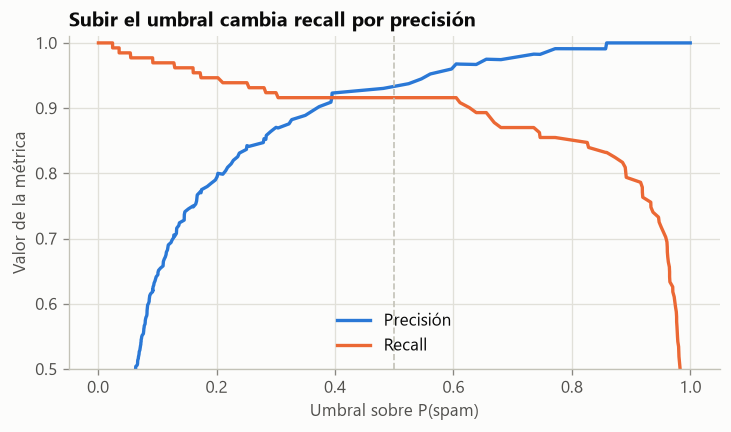

,precision_minima,umbral,precision,recall
0,0.95,0.561,0.952,0.916
1,0.98,0.736,0.983,0.870
2,0.99,0.772,0.991,0.855
3,1.00,0.859,1.000,0.832


In [5]:
model = train_model(ModelName.LOGREG, split.X_train, split.y_train)
proba = model.predict_proba(split.X_test)[:, 1]
precision, recall, thresholds = precision_recall_curve(split.y_test, proba)

fig, ax = plt.subplots(figsize=(7, 3.6), dpi=120)
ax.plot(thresholds, precision[:-1], color=BLUE, linewidth=2, label="Precisión")
ax.plot(thresholds, recall[:-1], color=ORANGE, linewidth=2, label="Recall")
ax.axvline(0.5, color="#c3c2b7", linewidth=1, linestyle="--")
ax.set_xlabel("Umbral sobre P(spam)")
ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0.5, 1.01)
ax.set_title("Subir el umbral cambia recall por precisión", loc="left", fontweight="bold")
ax.grid(True)
ax.legend()
plt.show()

rows = []
for target in (0.95, 0.98, 0.99, 1.0):
    i = int(np.argmax(precision[:-1] >= target))
    rows.append(
        {
            "precision_minima": target,
            "umbral": round(float(thresholds[i]), 3),
            "precision": round(float(precision[i]), 3),
            "recall": round(float(recall[i]), 3),
        }
    )
pd.DataFrame(rows)

## 4. Análisis de errores

Leer los fallos es la forma más rápida de saber qué mejorar.

In [6]:
errors = pd.DataFrame({"texto": split.X_test, "real": split.y_test, "p_spam": proba.round(3)})
errors["prediccion"] = (errors["p_spam"] > 0.5).astype(int)
errors = errors[errors["real"] != errors["prediccion"]]

print("Falsas alarmas (ham marcado como spam):")
display(errors[errors["real"] == 0].sort_values("p_spam", ascending=False)[["p_spam", "texto"]])
print("Spam no detectado:")
display(errors[errors["real"] == 1].sort_values("p_spam")[["p_spam", "texto"]])

Falsas alarmas (ham marcado como spam):


,p_spam,texto
474,0.857,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sm...
642,0.746,Your daily text from me – a favour this time
748,0.680,Dont you have message offer
694,0.638,"Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PI..."
212,0.597,I'm at work. Please call
221,0.561,Glad to see your reply.
128,0.546,Are you free now?can i call now?
744,0.524,I'm at home. Please call


Spam no detectado:


,p_spam,texto
486,0.024,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day,..."
280,0.036,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day ...
248,0.054,ringtoneking 84484
579,0.092,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT G...
273,0.128,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. ...
654,0.160,"Latest News! Police station toilet stolen, cops have nothing to go on!"
268,0.172,Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min
255,0.202,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
442,0.251,Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min Gsex POBOX 2667 WC1N 3XX
189,0.280,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super w...
